In [1]:
import sys
from pathlib import Path
assert Path(sys.prefix) == Path('/content/bike_sharing_entorno_limpio')
print('Kernel aislado confirmado:', sys.executable)

Kernel aislado confirmado: /content/bike_sharing_entorno_limpio/bin/python



# Fase 1 — Análisis exploratorio de datos

## Bike Sharing Analytics

Universidad de La Salle  
Maestría en Inteligencia Artificial  
Proyecto Integrador de Ciencia de Datos

### Naturaleza del notebook

Reconstrucción independiente del análisis exploratorio
integrado en el dashboard global.

No corresponde al notebook académico original de Fase 1.

### Formulación del problema

Identificar los patrones temporales, meteorológicos
y de comportamiento de los usuarios asociados con
la demanda diaria del sistema de bicicletas compartidas.

### Objetivo general

Analizar los factores asociados con la demanda de
bicicletas compartidas durante 2011 y 2012.

### Objetivos específicos

- Caracterizar la calidad y estructura del dataset.
- Identificar patrones temporales de demanda.
- Analizar la relación entre clima y alquileres.
- Identificar valores atípicos mediante IQR y Z-score.
- Generar evidencia descriptiva para las fases de modelado.

### Fuente de datos

UCI Machine Learning Repository — Bike Sharing Dataset.

DOI: 10.24432/C5W894

https://archive.ics.uci.edu/dataset/275/bike-sharing-dataset


In [2]:

# Localizar la raíz del repositorio.

from pathlib import Path
import sys
import hashlib

actual = Path.cwd().resolve()

candidatos = [actual, *actual.parents]

# Alternativa para Google Colab.

candidatos.append(
    Path("/content/Bike-Sharing-Analytics")
)

ROOT = next(
    (
        p for p in candidatos
        if (p / "data" / "day.csv").is_file()
        and (p / "requirements.txt").is_file()
    ),
    None
)

if ROOT is None:
    raise FileNotFoundError(
        "Descarga o clona el repositorio antes de ejecutar."
    )

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.utils.config import DATASET, RESULTS_DIR

HASH_ESPERADO = (
    "a6bcf826782d3c0fbfdcbeead17cd0884"
    "185a0dafe8ff10cd48a874ee7ba18be"
)

assert hashlib.sha256(
    DATASET.read_bytes()
).hexdigest() == HASH_ESPERADO

print("Repositorio:", ROOT)
print("Dataset:", DATASET)
print("Integridad del dataset: OK")


Repositorio: /content/Bike-Sharing-Analytics
Dataset: /content/Bike-Sharing-Analytics/data/day.csv
Integridad del dataset: OK


## 1. Carga y calidad de los datos

In [3]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import chi2_contingency

SALIDA = RESULTS_DIR / "reproduccion" / "fase1"

SALIDA.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATASET)

df["dteday"] = pd.to_datetime(df["dteday"])

df = df.sort_values("dteday").reset_index(drop=True)

calidad = pd.DataFrame({
    "indicador": [
        "Registros",
        "Variables",
        "Valores faltantes",
        "Filas duplicadas",
        "Fechas duplicadas",
        "Inconsistencias en demanda"
    ],
    "valor": [
        len(df),
        df.shape[1],
        df.isna().sum().sum(),
        df.duplicated().sum(),
        df["dteday"].duplicated().sum(),
        (df["cnt"] !=
         df["casual"] + df["registered"]).sum()
    ]
})

display(calidad)

assert df.shape == (731, 16)

calidad.to_csv(
    SALIDA / "calidad_datos.csv",
    index=False
)

display(df.head())


,indicador,valor
0,Registros,731
1,Variables,16
2,Valores faltantes,0
3,Filas duplicadas,0
4,Fechas duplicadas,0
5,Inconsistencias en demanda,0


,instant,dteday,season,yr,mnth,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,6,0,2,0.344167,0.363625,0.805833,0.160446,331,654,985
1,2,2011-01-02,1,0,1,0,0,0,2,0.363478,0.353739,0.696087,0.248539,131,670,801
2,3,2011-01-03,1,0,1,0,1,1,1,0.196364,0.189405,0.437273,0.248309,120,1229,1349
3,4,2011-01-04,1,0,1,0,2,1,1,0.200000,0.212122,0.590435,0.160296,108,1454,1562
4,5,2011-01-05,1,0,1,0,3,1,1,0.226957,0.229270,0.436957,0.186900,82,1518,1600



## 2. Caracterización y estadística descriptiva

La variable objetivo es cnt, correspondiente al
total diario de alquileres.

Las variables casual y registered son componentes
directos de cnt. Por tanto, no deben utilizarse como
predictores de la demanda total en los modelos.


In [4]:

diccionario = pd.DataFrame({
    "variable": df.columns,
    "tipo": df.dtypes.astype(str).values,
    "valores_unicos": df.nunique().values,
    "faltantes": df.isna().sum().values
})

display(diccionario)

diccionario.to_csv(
    SALIDA / "diccionario_estructura.csv",
    index=False
)

descriptivos = df.describe().T

display(descriptivos)

descriptivos.to_csv(
    SALIDA / "estadistica_descriptiva.csv"
)


,variable,tipo,valores_unicos,faltantes
0,instant,int64,731,0
1,dteday,datetime64[ns],731,0
2,season,int64,4,0
3,yr,int64,2,0
4,mnth,int64,12,0
5,holiday,int64,2,0
6,weekday,int64,7,0
7,workingday,int64,2,0
8,weathersit,int64,3,0
9,temp,float64,499,0


,count,mean,min,25%,50%,75%,max,std
instant,731.0,366.0,1.0,183.5,366.0,548.5,731.0,211.165812
dteday,731,2012-01-01 00:00:00,2011-01-01 00:00:00,2011-07-02 12:00:00,2012-01-01 00:00:00,2012-07-01 12:00:00,2012-12-31 00:00:00,NaN
season,731.0,2.49658,1.0,2.0,3.0,3.0,4.0,1.110807
yr,731.0,0.500684,0.0,0.0,1.0,1.0,1.0,0.500342
mnth,731.0,6.519836,1.0,4.0,7.0,10.0,12.0,3.451913
holiday,731.0,0.028728,0.0,0.0,0.0,0.0,1.0,0.167155
weekday,731.0,2.997264,0.0,1.0,3.0,5.0,6.0,2.004787
workingday,731.0,0.683995,0.0,0.0,1.0,1.0,1.0,0.465233
weathersit,731.0,1.395349,1.0,1.0,1.0,2.0,3.0,0.544894
temp,731.0,0.495385,0.05913,0.337083,0.498333,0.655417,0.861667,0.183051


## 3. Indicadores globales y temporales

In [5]:

total = int(df["cnt"].sum())

indicadores = {
    "registros": len(df),
    "alquileres_totales": total,
    "promedio_diario": float(df["cnt"].mean()),
    "mediana_diaria": float(df["cnt"].median()),
    "demanda_maxima": int(df["cnt"].max()),
    "demanda_minima": int(df["cnt"].min()),
    "alquileres_casuales": int(df["casual"].sum()),
    "alquileres_registrados": int(df["registered"].sum()),
    "participacion_registrados_pct":
        float(df["registered"].sum() / total * 100)
}

df_indicadores = pd.DataFrame(
    indicadores.items(),
    columns=["indicador", "valor"]
)

display(df_indicadores)

df_indicadores.to_csv(
    SALIDA / "indicadores_globales.csv",
    index=False
)

anual = df.groupby(
    df["dteday"].dt.year
)[["cnt", "casual", "registered"]].sum()

mensual = df.groupby(
    df["dteday"].dt.to_period("M")
)[["cnt", "casual", "registered"]].sum()

display(anual)
display(mensual)

anual.to_csv(SALIDA / "demanda_anual.csv")
mensual.to_csv(SALIDA / "demanda_mensual.csv")

crecimiento = (
    anual.loc[2012, "cnt"] /
    anual.loc[2011, "cnt"] - 1
) * 100

print("Crecimiento anual (%):", round(crecimiento, 4))


,indicador,valor
0,registros,7.310000e+02
1,alquileres_totales,3.292679e+06
2,promedio_diario,4.504349e+03
3,mediana_diaria,4.548000e+03
4,demanda_maxima,8.714000e+03
5,demanda_minima,2.200000e+01
6,alquileres_casuales,6.200170e+05
7,alquileres_registrados,2.672662e+06
8,participacion_registrados_pct,8.116983e+01


,cnt,casual,registered
dteday,,,
2011,1243103,247252,995851
2012,2049576,372765,1676811


,cnt,casual,registered
dteday,,,
2011-01,38189,3073,35116
2011-02,48215,6242,41973
2011-03,64045,12826,51219
2011-04,94870,22346,72524
2011-05,135821,31050,104771
2011-06,143512,30612,112900
2011-07,141341,36452,104889
2011-08,136691,28842,107849
2011-09,127418,26545,100873


Crecimiento anual (%): 64.8758



## 4. Análisis de correlaciones

Se utilizan Pearson y Spearman para estudiar
asociaciones lineales y monotónicas.

La correlación no implica causalidad.


,temp,atemp,hum,windspeed,casual,registered,cnt
temp,1.0000,0.9917,0.1270,-0.1579,0.5433,0.5400,0.6275
atemp,0.9917,1.0000,0.1400,-0.1836,0.5439,0.5442,0.6311
hum,0.1270,0.1400,1.0000,-0.2485,-0.0770,-0.0911,-0.1007
windspeed,-0.1579,-0.1836,-0.2485,1.0000,-0.1676,-0.2174,-0.2345
casual,0.5433,0.5439,-0.0770,-0.1676,1.0000,0.3953,0.6728
registered,0.5400,0.5442,-0.0911,-0.2174,0.3953,1.0000,0.9455
cnt,0.6275,0.6311,-0.1007,-0.2345,0.6728,0.9455,1.0000


,temp,atemp,hum,windspeed,casual,registered,cnt
temp,1.0000,0.9926,0.1299,-0.1472,0.6674,0.5312,0.6220
atemp,0.9926,1.0000,0.1396,-0.1690,0.6677,0.5319,0.6228
hum,0.1299,0.1396,1.0000,-0.2390,-0.0708,-0.0932,-0.0981
windspeed,-0.1472,-0.1690,-0.2390,1.0000,-0.1803,-0.2030,-0.2172
casual,0.6674,0.6677,-0.0708,-0.1803,1.0000,0.5236,0.7535
registered,0.5312,0.5319,-0.0932,-0.2030,0.5236,1.0000,0.9403
cnt,0.6220,0.6228,-0.0981,-0.2172,0.7535,0.9403,1.0000


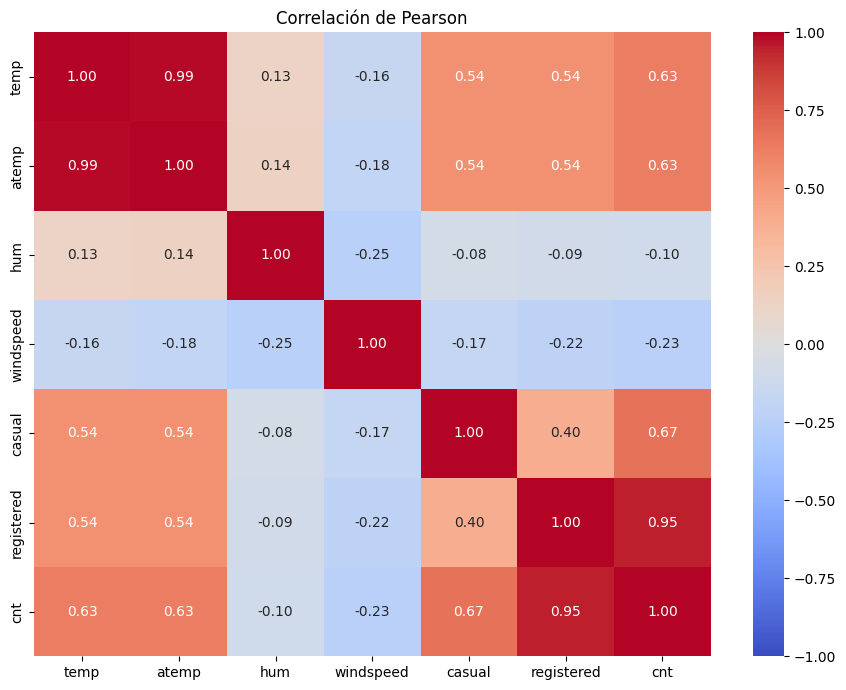

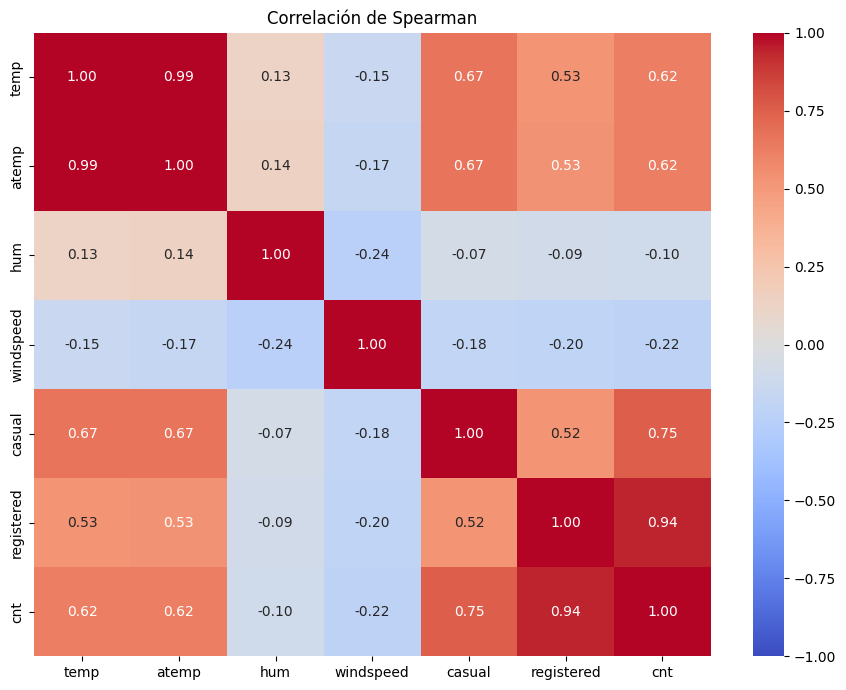

In [6]:

variables = [
    "temp", "atemp", "hum", "windspeed",
    "casual", "registered", "cnt"
]

pearson = df[variables].corr(method="pearson")
spearman = df[variables].corr(method="spearman")

display(pearson.round(4))
display(spearman.round(4))

pearson.to_csv(SALIDA / "correlacion_pearson.csv")
spearman.to_csv(SALIDA / "correlacion_spearman.csv")

for nombre, matriz in [
    ("pearson", pearson),
    ("spearman", spearman)
]:

    plt.figure(figsize=(9, 7))

    sns.heatmap(
        matriz,
        annot=True,
        fmt=".2f",
        cmap="coolwarm",
        vmin=-1,
        vmax=1
    )

    plt.title("Correlación de " + nombre.capitalize())
    plt.tight_layout()

    plt.savefig(
        SALIDA / f"correlacion_{nombre}.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()



## 5. Detección de valores atípicos

Se aplica el rango intercuartílico con factor 1.5
y Z-score con umbral absoluto de 3.

La detección es exploratoria. No se eliminan
registros ni se modifica el dataset.


,variable,limite_inferior_iqr,limite_superior_iqr,outliers_iqr,outliers_zscore
0,temp,-0.140416,1.132916,0,0
1,atemp,-0.068297,1.014741,0,0
2,hum,0.204687,1.045521,2,2
3,windspeed,-0.012447,0.380611,13,2
4,casual,-855.250000,2266.750000,44,8
5,registered,-922.250000,8195.750000,0,0
6,cnt,-1054.000000,10162.000000,0,0


Detecciones IQR: 59
Detecciones Z-score: 12


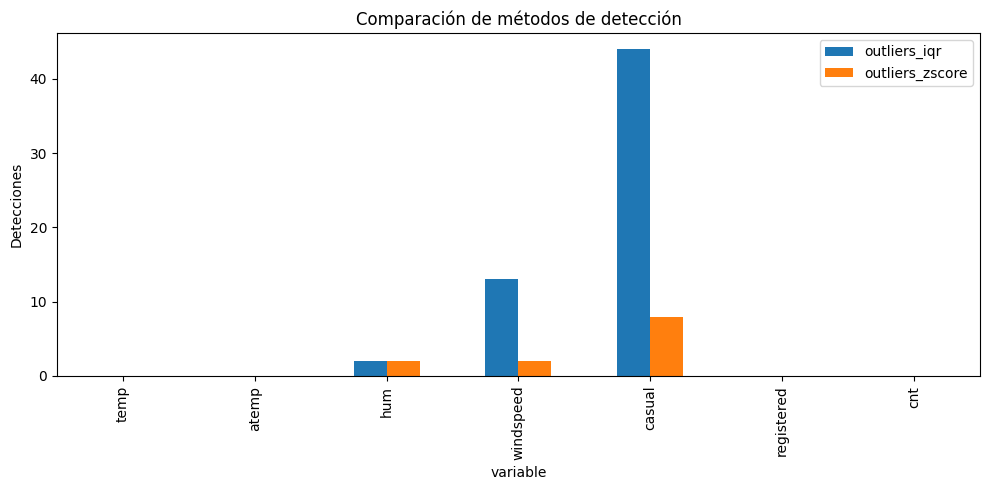

In [7]:

registros = []

for variable in variables:

    serie = df[variable]

    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)

    iqr = q3 - q1

    inferior = q1 - 1.5 * iqr
    superior = q3 + 1.5 * iqr

    mascara_iqr = (
        (serie < inferior) |
        (serie > superior)
    )

    z = (
        serie - serie.mean()
    ) / serie.std(ddof=0)

    registros.append({
        "variable": variable,
        "limite_inferior_iqr": inferior,
        "limite_superior_iqr": superior,
        "outliers_iqr": int(mascara_iqr.sum()),
        "outliers_zscore": int((z.abs() > 3).sum())
    })

outliers = pd.DataFrame(registros)

display(outliers)

outliers.to_csv(
    SALIDA / "deteccion_outliers.csv",
    index=False
)

print(
    "Detecciones IQR:",
    outliers["outliers_iqr"].sum()
)

print(
    "Detecciones Z-score:",
    outliers["outliers_zscore"].sum()
)

outliers.set_index("variable")[
    ["outliers_iqr", "outliers_zscore"]
].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Comparación de métodos de detección")
plt.ylabel("Detecciones")
plt.tight_layout()

plt.savefig(
    SALIDA / "comparacion_outliers.png",
    dpi=150
)

plt.show()
plt.close()


## 6. Visualizaciones de demanda

,count,mean,median,sum
clima,,,,
Despejado,463,4876.786177,4844.0,2257952
Lluvia o nieve ligera,21,1803.285714,1817.0,37869
Niebla o nublado,247,4035.862348,4040.0,996858


,count,mean,median,sum
estacion,,,,
Invierno,181,2604.132597,2209.0,471348
Otoño,178,4728.162921,4634.5,841613
Primavera,184,4992.331522,4941.5,918589
Verano,188,5644.303191,5353.5,1061129


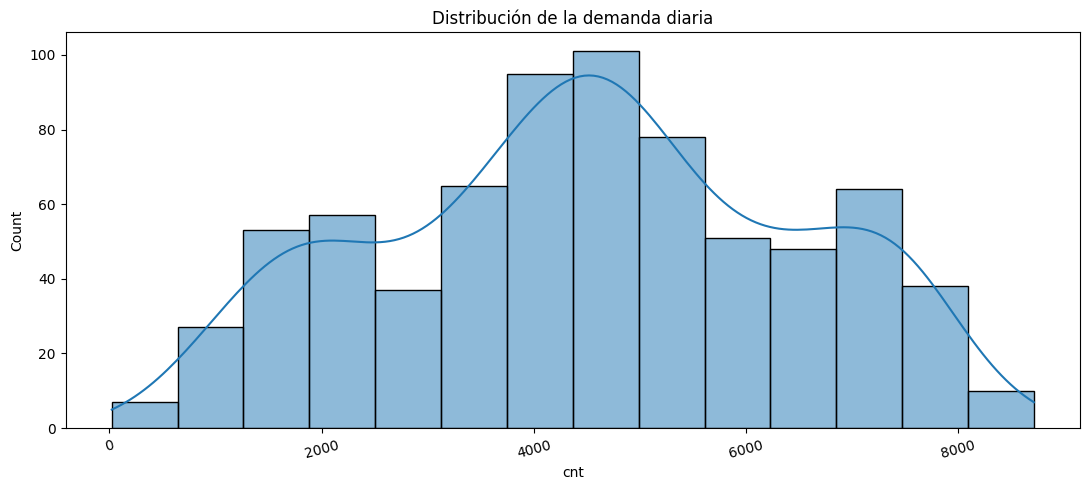

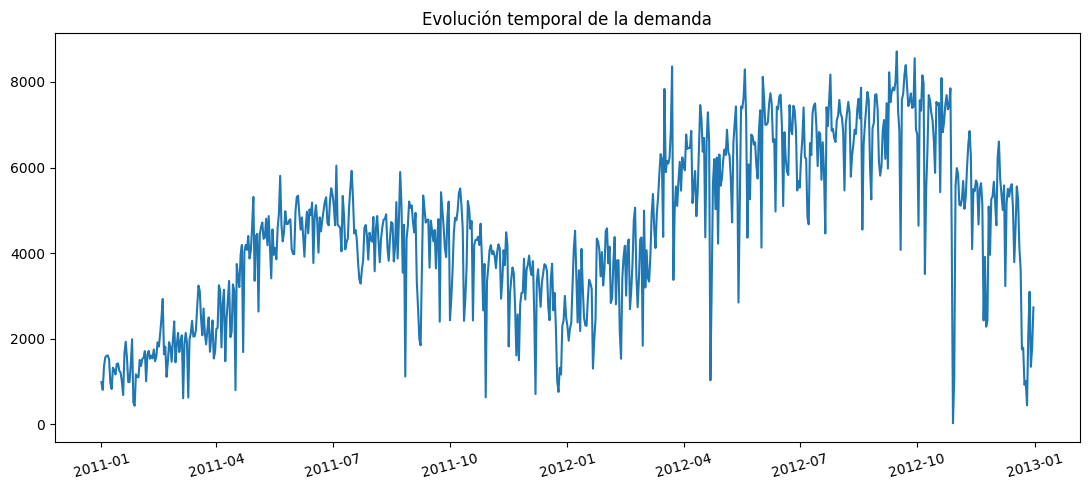

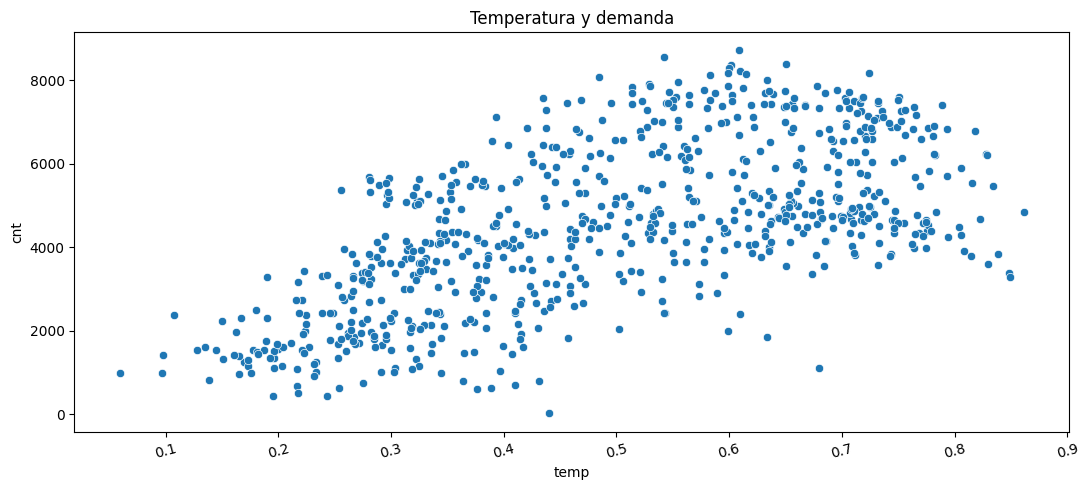

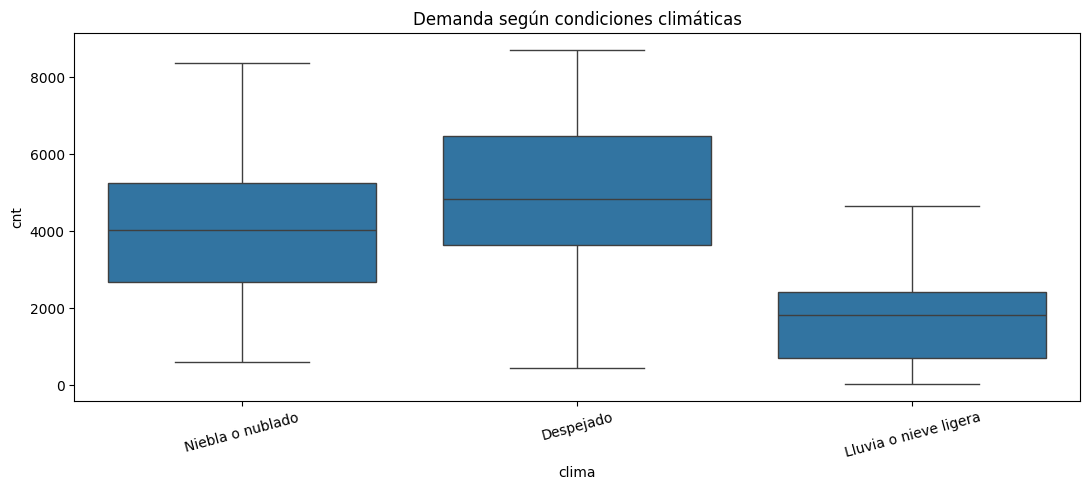

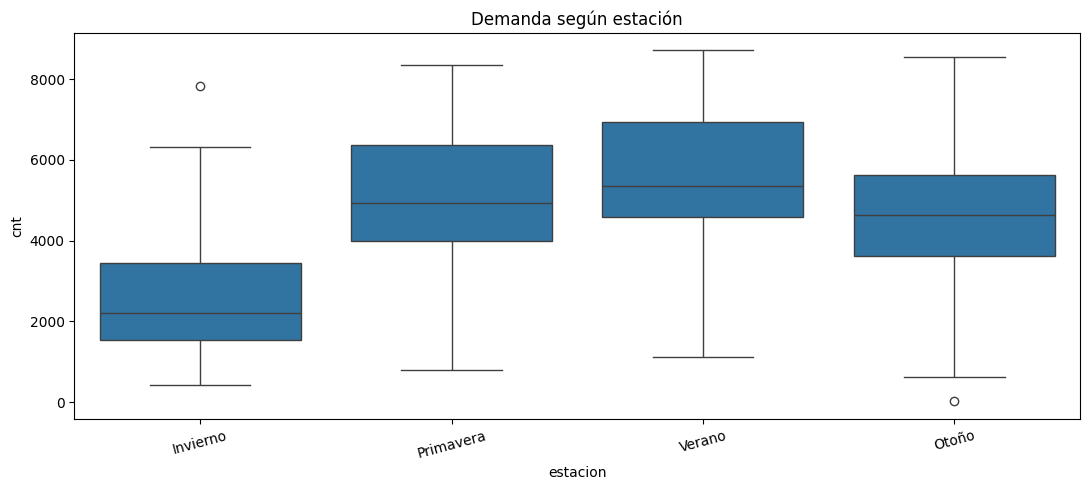

In [8]:

estaciones = {
    1: "Invierno",
    2: "Primavera",
    3: "Verano",
    4: "Otoño"
}

climas = {
    1: "Despejado",
    2: "Niebla o nublado",
    3: "Lluvia o nieve ligera",
    4: "Clima severo"
}

df_eda = df.assign(
    estacion=df["season"].map(estaciones),
    clima=df["weathersit"].map(climas)
)

demanda_clima = df_eda.groupby("clima")["cnt"].agg(
    ["count", "mean", "median", "sum"]
)

demanda_estacion = df_eda.groupby("estacion")["cnt"].agg(
    ["count", "mean", "median", "sum"]
)

display(demanda_clima)
display(demanda_estacion)

demanda_clima.to_csv(SALIDA / "demanda_clima.csv")
demanda_estacion.to_csv(SALIDA / "demanda_estacion.csv")

graficas = [
    (
        "histograma_demanda",
        lambda: sns.histplot(df["cnt"], kde=True),
        "Distribución de la demanda diaria"
    ),
    (
        "demanda_diaria",
        lambda: plt.plot(df["dteday"], df["cnt"]),
        "Evolución temporal de la demanda"
    ),
    (
        "temperatura_demanda",
        lambda: sns.scatterplot(
            data=df, x="temp", y="cnt"
        ),
        "Temperatura y demanda"
    ),
    (
        "demanda_clima",
        lambda: sns.boxplot(
            data=df_eda, x="clima", y="cnt"
        ),
        "Demanda según condiciones climáticas"
    ),
    (
        "demanda_estacion",
        lambda: sns.boxplot(
            data=df_eda, x="estacion", y="cnt"
        ),
        "Demanda según estación"
    )
]

for nombre, funcion, titulo in graficas:

    plt.figure(figsize=(11, 5))

    funcion()

    plt.title(titulo)
    plt.xticks(rotation=15)
    plt.tight_layout()

    plt.savefig(
        SALIDA / f"{nombre}.png",
        dpi=150,
        bbox_inches="tight"
    )

    plt.show()
    plt.close()



## 7. Análisis de asociación categórica

Se utiliza la prueba Chi-cuadrado y V de Cramér.

Se aplica corrección de Bonferroni para controlar
las comparaciones múltiples.

La dependencia temporal entre observaciones limita
la interpretación inferencial de estas pruebas.


In [9]:

pares = [
    ("season", "weathersit"),
    ("weekday", "weathersit"),
    ("workingday", "weathersit"),
    ("holiday", "weathersit")
]

resultados_chi = []

for variable1, variable2 in pares:

    tabla = pd.crosstab(
        df[variable1],
        df[variable2]
    )

    chi2, p, gl, esperadas = chi2_contingency(
        tabla,
        correction=False
    )

    n = tabla.to_numpy().sum()

    denominador = n * min(
        tabla.shape[0] - 1,
        tabla.shape[1] - 1
    )

    cramer = np.sqrt(
        chi2 / denominador
    )

    resultados_chi.append({
        "variable_1": variable1,
        "variable_2": variable2,
        "chi2": chi2,
        "p_valor": p,
        "p_ajustado": min(p * len(pares), 1),
        "grados_libertad": gl,
        "v_cramer": cramer,
        "esperadas_menores_5_pct":
            float((esperadas < 5).mean() * 100)
    })

df_chi = pd.DataFrame(resultados_chi)

display(df_chi)

df_chi.to_csv(
    SALIDA / "pruebas_chi_cuadrado.csv",
    index=False
)


,variable_1,variable_2,chi2,p_valor,p_ajustado,grados_libertad,v_cramer,esperadas_menores_5_pct
0,season,weathersit,14.883886,0.021179,0.084717,6,0.100898,0.000000
1,weekday,weathersit,14.357575,0.278459,1.000000,12,0.099098,33.333333
2,workingday,weathersit,2.742701,0.253764,1.000000,2,0.061253,0.000000
3,holiday,weathersit,1.018796,0.600857,1.000000,2,0.037332,16.666667



## 8. Conclusiones

Los resultados descriptivos permiten identificar
patrones temporales y meteorológicos asociados
con la demanda.

Las correlaciones entre temperatura y sensación
térmica deben considerarse durante la selección
de características.

La detección de valores atípicos no implica
automáticamente su eliminación.

Las variables casual y registered deben excluirse
como predictores de cnt para prevenir fuga de datos.

El análisis exploratorio proporciona la base para
las siguientes fases de regresión, modelado avanzado
y preprocesamiento.


In [10]:

import json

resumen_fase1 = {
    "fase": 1,
    "tipo": "Reconstrucción independiente",
    "filas": int(len(df)),
    "columnas": int(df.shape[1]),
    "alquileres_totales": int(df["cnt"].sum()),
    "crecimiento_anual_pct": float(crecimiento),
    "detecciones_iqr": int(outliers["outliers_iqr"].sum()),
    "detecciones_zscore": int(
        outliers["outliers_zscore"].sum()
    ),
    "registros_eliminados": 0,
    "modelos_entrenados": 0
}

(SALIDA / "resumen_fase1.json").write_text(
    json.dumps(
        resumen_fase1,
        indent=4,
        ensure_ascii=False
    ),
    encoding="utf-8"
)

print("=== RESULTADOS FASE 1 ===")

for clave, valor in resumen_fase1.items():
    print(f"{clave}: {valor}")

print("\nEvidencias generadas:")

for archivo in sorted(SALIDA.iterdir()):
    print(" -", archivo.name)


=== RESULTADOS FASE 1 ===
fase: 1
tipo: Reconstrucción independiente
filas: 731
columnas: 16
alquileres_totales: 3292679
crecimiento_anual_pct: 64.87579870694545
detecciones_iqr: 59
detecciones_zscore: 12
registros_eliminados: 0
modelos_entrenados: 0

Evidencias generadas:
 - calidad_datos.csv
 - comparacion_outliers.png
 - correlacion_pearson.csv
 - correlacion_pearson.png
 - correlacion_spearman.csv
 - correlacion_spearman.png
 - demanda_anual.csv
 - demanda_clima.csv
 - demanda_clima.png
 - demanda_diaria.png
 - demanda_estacion.csv
 - demanda_estacion.png
 - demanda_mensual.csv
 - deteccion_outliers.csv
 - diccionario_estructura.csv
 - estadistica_descriptiva.csv
 - histograma_demanda.png
 - indicadores_globales.csv
 - pruebas_chi_cuadrado.csv
 - resumen_fase1.json
 - temperatura_demanda.png
